# Notebook 09 — Evaluasi & Diagnosa Bias Model LSTM pada Prediksi Arah Time Series (Data Real)

**Tujuan notebook:**
Notebook ini secara khusus membahas masalah klasik yang sangat sering terjadi ketika melatih
model *deep learning* (LSTM) untuk memprediksi **arah pergerakan** harga/indeks (naik/turun):
model "kolaps" dan hanya menebak satu kelas mayoritas (misalnya selalu memprediksi **UP**).

> **Note:** Versi ini memakai **data REAL** proyek — bukan lagi data sintetis — yaitu gabungan
> harga OHLCV S&P 500 (`data/raw/stocks/GSPC_2018_2024.csv`) dan skor sentimen berita harian
> (`data/processed/sentiment/headlines_daily_sentiment.csv`). Karena datanya real, imbalance dan
> kekuatan sinyal **tidak lagi bisa kita kontrol** seperti versi sintetis sebelumnya — hasil di
> BAB 4/5 dilaporkan apa adanya, termasuk kalau ternyata teknik perbaikan tidak sepenuhnya
> menghilangkan bias (ini realistis untuk data pasar finansial yang sangat noisy/mendekati
> *efficient market*).

**Alur pembahasan:**
1. **BAB 1** — Load & gabungkan data real (OHLCV + sentimen) + preprocessing yang benar.
2. **BAB 2** — Reproduksi masalah: melatih LSTM standar yang berujung bias/kolaps.
3. **BAB 3** — Diagnosa data & deteksi model bias secara kuantitatif dan visual.
4. **BAB 4** — Tiga strategi perbaikan: *class weighting*, *threshold tuning*, dan *feature engineering*.
5. **BAB 5** — Evaluasi akhir, tabel komparasi, dan checklist debugging untuk model time series.

## BAB 1 — Setup & Penggabungan Data Real (OHLCV + Sentimen) dengan Preprocessing yang Benar

Sebelum masuk ke pemodelan, kita siapkan terlebih dahulu:
1. Import library dan penetapan *random seed* agar hasil dapat direproduksi.
2. Load data **REAL**: harga OHLCV S&P 500 mentah + skor sentimen berita harian (hasil pipeline
   sentimen proyek ini), lalu **digabungkan (inner join)** berdasarkan tanggal.
3. Preprocessing yang benar:
   - Membersihkan data OHLCV mentah (buang kolom tidak relevan, validasi, tangani NaN).
   - Menghitung **log return**, bukan harga mentah, karena log return lebih stasioner.
   - **Windowing/sequence generation** dengan panjang *lookback* tertentu.
   - **Scaling yang benar**: `MinMaxScaler` di-*fit* hanya pada data **train**, lalu di-*transform*
     ke data **val** dan **test** — untuk mencegah *data leakage*.

In [56]:
# =============================================================================
# 1.1 IMPORT LIBRARY & SETUP REPRODUCIBILITY
# =============================================================================
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, precision_recall_curve,
    roc_auc_score, roc_curve, f1_score, precision_score, recall_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# --- Random seed untuk reproduksibilitas penuh ---
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

print("PyTorch version :", torch.__version__)
print("Device digunakan:", DEVICE)
print("Seed digunakan  :", SEED)

# Resolusi PROJECT_ROOT -- robust baik dijalankan dari stock_prediction/notebooks/
# (Jupyter normal) maupun dari stock_prediction/ langsung (mis. lewat nbconvert/script).
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
print("PROJECT_ROOT    :", PROJECT_ROOT)

PyTorch version : 2.6.0+cu124
Device digunakan: cuda
Seed digunakan  : 42
PROJECT_ROOT    : e:\forecasting_index_snp500\stock_prediction


### 1.2 Load & Bersihkan Data OHLCV Mentah (Real)

Data harga S&P 500 (`^GSPC`) mentah dibaca dari `data/raw/stocks/GSPC_2018_2024.csv`.
Preprocessing dasar yang diterapkan (mirror `StockPreprocessor` milik pipeline proyek ini):
- Buang kolom yang tidak relevan untuk pemodelan (`Dividends`, `Stock Splits`).
- Urutkan berdasarkan tanggal, buang duplikat tanggal (kalau ada).
- Validasi nilai harga (> 0) dan tangani NaN (forward-fill lalu backward-fill).

In [57]:
# =============================================================================
# 1.2 LOAD & BERSIHKAN DATA OHLCV MENTAH (REAL)
# =============================================================================
STOCK_RAW_PATH = PROJECT_ROOT / "data" / "raw" / "stocks" / "GSPC_2018_2024.csv"

df_stock = pd.read_csv(STOCK_RAW_PATH, parse_dates=["Date"])
df_stock = df_stock.drop(columns=[c for c in ["Dividends", "Stock Splits"] if c in df_stock.columns])
df_stock = df_stock.sort_values("Date").drop_duplicates(subset="Date").reset_index(drop=True)

# Validasi & penanganan NaN (forward-fill -> backward-fill), sesuai kaidah preprocessing time series
assert (df_stock[["Open", "High", "Low", "Close"]] > 0).all().all(), "Ditemukan harga <= 0"
df_stock = df_stock.ffill().bfill()

print(f"OHLCV mentah dimuat: {len(df_stock)} baris ({df_stock['Date'].min().date()} - {df_stock['Date'].max().date()})")
df_stock.head()

OHLCV mentah dimuat: 1552 baris (2018-01-02 - 2024-03-04)


,Date,Open,High,Low,Close,Volume
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000


### 1.3 Load Data Sentimen Harian (Real, Hasil Pipeline Sentimen Proyek)

Skor sentimen harian (`sentiment_mean`, agregasi FinBERT atas headline berita per hari) dibaca
dari `data/processed/sentiment/headlines_daily_sentiment.csv` — file ini sudah diproses oleh
pipeline sentimen proyek (`app/services/sentiment_service.py`), jadi di sini kita tinggal memuatnya.

In [58]:
# =============================================================================
# 1.3 LOAD DATA SENTIMEN HARIAN (REAL)
# =============================================================================
SENTIMENT_PATH = PROJECT_ROOT / "data" / "processed" / "sentiment" / "headlines_daily_sentiment.csv"

df_sentiment = pd.read_csv(SENTIMENT_PATH, parse_dates=["Date"])
df_sentiment = df_sentiment[["Date", "sentiment_mean"]].sort_values("Date").reset_index(drop=True)

print(f"Sentimen harian dimuat: {len(df_sentiment)} baris ({df_sentiment['Date'].min().date()} - {df_sentiment['Date'].max().date()})")
df_sentiment.head()

Sentimen harian dimuat: 3504 baris (2008-01-02 - 2024-03-04)


,Date,sentiment_mean
0,2008-01-02,-0.522108
1,2008-01-03,0.861627
2,2008-01-07,0.586567
3,2008-01-09,-0.421696
4,2008-01-10,0.542341


### 1.4 Gabungkan (Inner Join) OHLCV + Sentimen berdasarkan Tanggal

Kita gabungkan dua sumber data real ini dengan **inner join** pada kolom `Date` — hanya
tanggal yang punya kedua jenis data (harga DAN sentimen) yang dipakai. Ini konsisten dengan
pendekatan `load_joined()` di `pipeline/feature_engineering/dataset_builder.py` (modul produksi
proyek ini).

In [59]:
# =============================================================================
# 1.4 GABUNGKAN (INNER JOIN) OHLCV + SENTIMEN
# =============================================================================
df_price = pd.merge(
    df_stock[["Date", "Open", "High", "Low", "Close", "Volume"]],
    df_sentiment,
    on="Date",
    how="inner",
).sort_values("Date").reset_index(drop=True)

print(f"Dataset gabungan: {len(df_price)} baris ({df_price['Date'].min().date()} - {df_price['Date'].max().date()})")
df_price.head()

Dataset gabungan: 1528 baris (2018-01-02 - 2024-03-04)


,Date,Open,High,Low,Close,Volume,sentiment_mean
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.311223
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,-0.018505
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.000000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.071510
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.152372


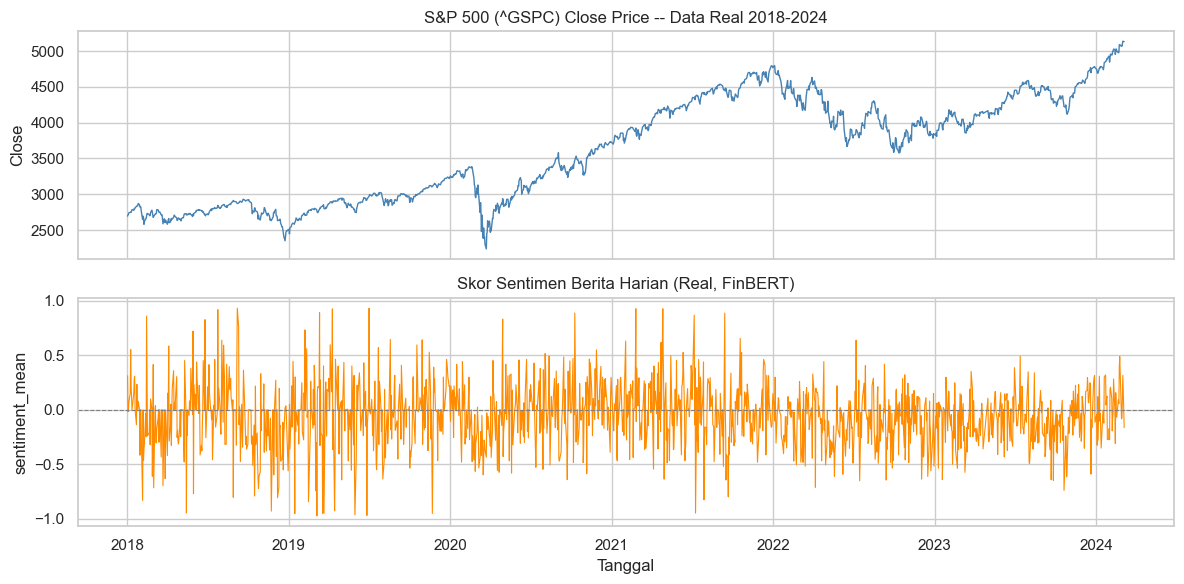

In [60]:
# Visualisasi cepat: harga Close (real) vs sentimen harian (real)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df_price["Date"], df_price["Close"], color="steelblue", linewidth=1)
axes[0].set_title("S&P 500 (^GSPC) Close Price -- Data Real 2018-2024")
axes[0].set_ylabel("Close")

axes[1].plot(df_price["Date"], df_price["sentiment_mean"], color="darkorange", linewidth=0.8)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Skor Sentimen Berita Harian (Real, FinBERT)")
axes[1].set_ylabel("sentiment_mean")
axes[1].set_xlabel("Tanggal")

plt.tight_layout()
plt.show()

### 1.5 Preprocessing Langkah 1 — Log Return

Kita menghitung **log return** karena:
- Log return lebih **stasioner** dibanding harga mentah (mean & variance lebih stabil).
- Cocok dijumlahkan langsung untuk return multi-periode (`sum` log return = compounded return).

$$ r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) $$

Label arah pergerakan (**target klasifikasi biner**) didefinisikan sebagai:

$$ y_t = \begin{cases} 1 & \text{(UP)}, & \text{jika } r_t > 0 \\ 0 & \text{(DOWN)}, & \text{jika } r_t \le 0 \end{cases} $$

In [61]:
# =============================================================================
# 1.5 LOG RETURN & LABEL ARAH PERGERAKAN
# =============================================================================
df = df_price.copy()
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))
df["direction"] = (df["log_return"] > 0).astype(int)  # 1 = UP, 0 = DOWN
df = df.dropna().reset_index(drop=True)

class_ratio = df["direction"].value_counts(normalize=True).sort_index()
print("Distribusi kelas keseluruhan (0=DOWN, 1=UP) -- DATA REAL:")
print(class_ratio)
print(f"\nRasio imbalance UP:DOWN sekitar {class_ratio[1]*100:.1f}% : {class_ratio[0]*100:.1f}%")

df.head()

Distribusi kelas keseluruhan (0=DOWN, 1=UP) -- DATA REAL:
direction
0    0.46038
1    0.53962
Name: proportion, dtype: float64

Rasio imbalance UP:DOWN sekitar 54.0% : 46.0%


,Date,Open,High,Low,Close,Volume,sentiment_mean,log_return,direction
0,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,-0.018505,0.006378,1
1,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.000000,0.004021,1
2,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.071510,0.007009,1
3,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.152372,0.001661,1
4,2018-01-09,2751.149902,2759.139893,2747.860107,2751.290039,3467460000,0.551667,0.001302,1


### 1.6 Preprocessing Langkah 2 — Windowing / Sequence Generation

Model LSTM membutuhkan input berbentuk *sequence*. Kita membuat window sepanjang `LOOKBACK`
langkah waktu dari fitur **`log_return` + `sentiment_mean`** (gabungan sinyal harga & sentimen
real) untuk memprediksi **arah return pada langkah berikutnya** (`t+1`), sehingga tidak ada
informasi masa depan yang bocor ke input (*no leakage*).

In [62]:
# =============================================================================
# 1.6 WINDOWING / SEQUENCE GENERATION
# =============================================================================
LOOKBACK = 30

def create_sequences(feature_array, label_array, lookback=LOOKBACK):
    """
    Membentuk sequence (X) dan target (y) dari array fitur & label.
    X[i] = feature_array[i : i+lookback]           -> window lookback langkah
    y[i] = label_array[i+lookback]                  -> label pada langkah SETELAH window
    Dengan demikian window hanya berisi informasi masa lalu terhadap target -> no leakage.
    """
    X, y = [], []
    for i in range(len(feature_array) - lookback):
        X.append(feature_array[i:i + lookback])
        y.append(label_array[i + lookback])
    return np.array(X), np.array(y)

feature_cols = ["log_return", "sentiment_mean"]
X_all, y_all = create_sequences(df[feature_cols].values, df["direction"].values, LOOKBACK)
print("Fitur yang digunakan:", feature_cols)
print("Shape X_all :", X_all.shape, " (samples, timesteps, n_features)")
print("Shape y_all :", y_all.shape)

Fitur yang digunakan: ['log_return', 'sentiment_mean']
Shape X_all : (1497, 30, 2)  (samples, timesteps, n_features)
Shape y_all : (1497,)


### 1.7 Preprocessing Langkah 3 — Split Train/Val/Test (kronologis) & Scaling yang Benar

Karena ini data **time series**, split dilakukan **secara kronologis** (tanpa *shuffle*):
`train -> val -> test` berurutan mengikuti waktu.

> **Penting — mencegah data leakage:** `MinMaxScaler` hanya di-`fit()` pada `X_train`,
> lalu `transform()` (bukan `fit_transform()`) diterapkan ke `X_val` dan `X_test`.
> Jika scaler di-*fit* pada seluruh dataset, informasi statistik dari data val/test
> (masa depan) akan "bocor" ke proses training.

In [63]:
# =============================================================================
# 1.7 SPLIT KRONOLOGIS (TRAIN 70% / VAL 15% / TEST 15%) -- TANPA SHUFFLE
# =============================================================================
n_samples = len(X_all)
train_end = int(n_samples * 0.70)
val_end = int(n_samples * 0.85)

X_train_raw, y_train = X_all[:train_end], y_all[:train_end]
X_val_raw, y_val = X_all[train_end:val_end], y_all[train_end:val_end]
X_test_raw, y_test = X_all[val_end:], y_all[val_end:]

print(f"Train : {X_train_raw.shape[0]} samples")
print(f"Val   : {X_val_raw.shape[0]} samples")
print(f"Test  : {X_test_raw.shape[0]} samples")

Train : 1047 samples
Val   : 225 samples
Test  : 225 samples


In [64]:
# =============================================================================
# 1.8 PROPER SCALING -- fit HANYA pada X_train, transform ke X_val & X_test
# =============================================================================
n_features = X_train_raw.shape[2]

scaler = MinMaxScaler(feature_range=(0, 1))

# Fit hanya pada train: reshape ke 2D (samples*timesteps, features) untuk fitting scaler
scaler.fit(X_train_raw.reshape(-1, n_features))

def scale_sequences(X_raw, fitted_scaler, n_feat=n_features):
    original_shape = X_raw.shape
    X_2d = X_raw.reshape(-1, n_feat)
    X_scaled_2d = fitted_scaler.transform(X_2d)
    return X_scaled_2d.reshape(original_shape)

X_train = scale_sequences(X_train_raw, scaler)
X_val = scale_sequences(X_val_raw, scaler)
X_test = scale_sequences(X_test_raw, scaler)

print("Scaler di-fit HANYA pada X_train. X_val & X_test hanya di-transform.")
print("Range X_train setelah scaling :", X_train.min(), "-", X_train.max())

Scaler di-fit HANYA pada X_train. X_val & X_test hanya di-transform.
Range X_train setelah scaling : 0.0 - 1.0


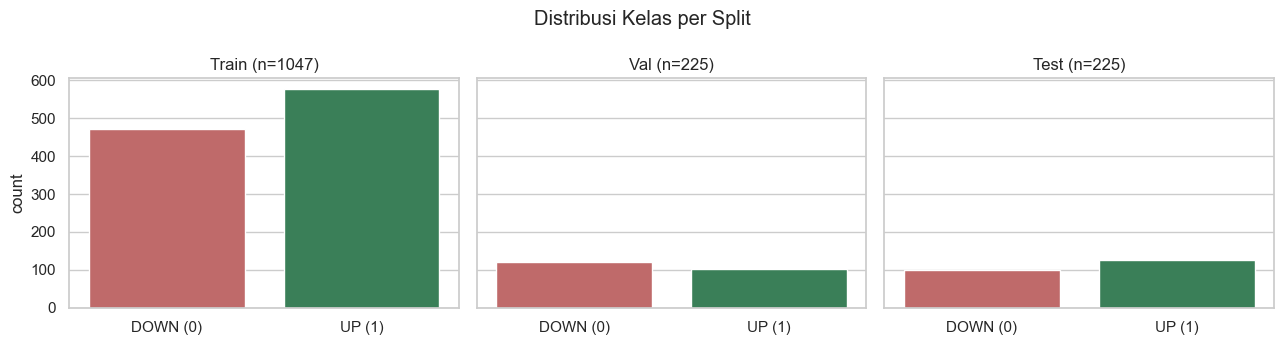

In [65]:
# Visualisasi distribusi kelas per split -- baseline pemahaman awal soal imbalance
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, y_split) in zip(axes, [("Train", y_train), ("Val", y_val), ("Test", y_test)]):
    sns.countplot(x=y_split, ax=ax, hue=y_split, palette={0: "indianred", 1: "seagreen"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["DOWN (0)", "UP (1)"])
    ax.set_title(f"{name} (n={len(y_split)})")
    ax.set_xlabel("")
plt.suptitle("Distribusi Kelas per Split")
plt.tight_layout()
plt.show()

## BAB 2 — Reproduksi Masalah (Building the Biased LSTM)

Kita bangun model LSTM **standar/naif**: arsitektur sederhana dengan output `sigmoid`
untuk klasifikasi biner, dilatih menggunakan `binary_crossentropy` **tanpa** penanganan
apapun terhadap *imbalance* maupun noise pada data.

> **Ekspektasi:** karena label bersifat *imbalanced* (~60% UP) dan sinyal (log return)
> sangat noisy, optimizer akan menemukan "jalan pintas" berupa *local minima* di mana model
> cukup menebak **UP** terus-menerus untuk meminimalkan loss rata-rata — inilah **model collapse**.

In [66]:
# =============================================================================
# 2.1 ARSITEKTUR LSTM STANDAR (TANPA HANDLING IMBALANCE)
# =============================================================================
# Catatan: proyek ini memakai PyTorch sebagai framework deep learning utama
# (lihat models/lstm/notebook07_trainer.py), sehingga notebook ini pun konsisten
# menggunakan PyTorch. Output layer tetap 1 unit + sigmoid (binary classification),
# setara dengan `Dense(1, activation='sigmoid')` + `binary_crossentropy` di Keras.
class SimpleLSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)      # h_n: (1, batch, hidden_size)
        h_last = h_n[-1]                # (batch, hidden_size) -> hidden state terakhir
        out = self.relu(self.fc1(h_last))
        logit = self.fc2(out).squeeze(-1)   # raw logit (sigmoid diterapkan di loss/prediksi)
        return logit

def build_baseline_lstm(n_features):
    return SimpleLSTMClassifier(n_features=n_features, hidden_size=32).to(DEVICE)

baseline_model = build_baseline_lstm(n_features=n_features)
print(baseline_model)
n_params = sum(p.numel() for p in baseline_model.parameters())
print(f"Total parameter: {n_params:,}")

SimpleLSTMClassifier(
  (lstm): LSTM(2, 32, batch_first=True)
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)
Total parameter: 5,153


In [67]:
# =============================================================================
# 2.2 UTILITAS TRAINING & EVALUASI (dipakai ulang di BAB 2 & BAB 4)
# =============================================================================
def to_tensor(X, y=None):
    X_t = torch.tensor(X, dtype=torch.float32)
    if y is None:
        return X_t
    y_t = torch.tensor(y, dtype=torch.float32)
    return X_t, y_t

def train_lstm_model(model, X_train_np, y_train_np, X_val_np, y_val_np,
                      epochs=30, batch_size=32, pos_weight=None,
                      early_stopping_patience=None, lr=1e-3):
    """
    Loop training standar PyTorch. `pos_weight` (scalar tensor) setara dengan
    `class_weight` di Keras untuk kelas positif (UP) pada BCEWithLogitsLoss.
    """
    X_train_t, y_train_t = to_tensor(X_train_np, y_train_np)
    X_val_t, y_val_t = to_tensor(X_val_np, y_val_np)
    X_val_t, y_val_t = X_val_t.to(DEVICE), y_val_t.to(DEVICE)

    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                               batch_size=batch_size, shuffle=True)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best_val_loss, patience_counter, best_state = np.inf, 0, None

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, n_seen = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            running_correct += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
            n_seen += xb.size(0)

        train_loss = running_loss / n_seen
        train_acc = running_correct / n_seen

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            val_acc = ((torch.sigmoid(val_logits) > 0.5).float() == y_val_t).float().mean().item()

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if early_stopping_patience is not None:
            if val_loss < best_val_loss - 1e-5:
                best_val_loss, patience_counter = val_loss, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                patience_counter += 1
                if patience_counter >= early_stopping_patience:
                    break

    if early_stopping_patience is not None and best_state is not None:
        model.load_state_dict(best_state)  # restore_best_weights

    return history

def predict_probs(model, X_np):
    model.eval()
    with torch.no_grad():
        logits = model(to_tensor(X_np).to(DEVICE))
        probs = torch.sigmoid(logits).cpu().numpy()
    return probs

In [68]:
# =============================================================================
# 2.3 TRAINING MODEL BASELINE (BIAS) -- TANPA class_weight
# =============================================================================
history_baseline = train_lstm_model(
    baseline_model, X_train, y_train, X_val, y_val,
    epochs=30, batch_size=32, pos_weight=None,
)
print("Training selesai.")
print(f"Loss akhir  -> train: {history_baseline['loss'][-1]:.4f} | val: {history_baseline['val_loss'][-1]:.4f}")
print(f"Acc akhir   -> train: {history_baseline['accuracy'][-1]:.4f} | val: {history_baseline['val_accuracy'][-1]:.4f}")

Training selesai.
Loss akhir  -> train: 0.6878 | val: 0.7054
Acc akhir   -> train: 0.5501 | val: 0.4578


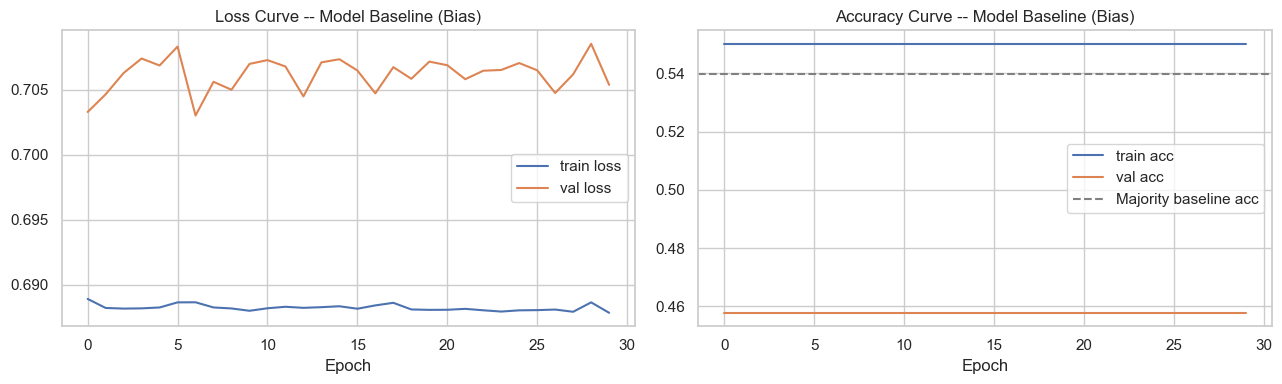

In [69]:
# Plot kurva loss & accuracy -- amati apakah loss "mentok"/plateau di local minima
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_baseline["loss"], label="train loss")
axes[0].plot(history_baseline["val_loss"], label="val loss")
axes[0].set_title("Loss Curve -- Model Baseline (Bias)")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_baseline["accuracy"], label="train acc")
axes[1].plot(history_baseline["val_accuracy"], label="val acc")
axes[1].axhline(class_ratio[1], color="gray", linestyle="--", label="Majority baseline acc")
axes[1].set_title("Accuracy Curve -- Model Baseline (Bias)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

> **Observasi:** Perhatikan bahwa `val_accuracy` model konvergen mendekati garis putus-putus
> abu-abu (*majority baseline accuracy* — akurasi jika model menebak UP terus-menerus).
> Ini adalah indikasi awal kuat bahwa model **tidak benar-benar belajar sinyal**, melainkan
> hanya "menghafal" proporsi kelas mayoritas. Mari kita buktikan secara kuantitatif di BAB 3.

In [70]:
# =============================================================================
# 2.4 CEK CEPAT: APAKAH MODEL HANYA MENEBAK SATU KELAS?
# =============================================================================
baseline_probs_test = predict_probs(baseline_model, X_test)
baseline_preds_test = (baseline_probs_test > 0.5).astype(int)

unique, counts = np.unique(baseline_preds_test, return_counts=True)
pred_distribution = dict(zip(unique, counts))
print("Distribusi prediksi model baseline pada data test:", pred_distribution)
print(f"Persentase prediksi UP : {pred_distribution.get(1, 0) / len(baseline_preds_test) * 100:.2f}%")
print(f"Persentase prediksi DOWN : {pred_distribution.get(0, 0) / len(baseline_preds_test) * 100:.2f}%")

Distribusi prediksi model baseline pada data test: {np.int64(1): np.int64(225)}
Persentase prediksi UP : 100.00%
Persentase prediksi DOWN : 0.00%


## BAB 3 — Diagnosa Data & Deteksi Model Bias

Sekarang kita bedah masalahnya secara sistematis dengan 4 alat diagnosa:
1. **Analisis distribusi target** di setiap split.
2. **Distribusi probabilitas prediksi** (histogram output sigmoid).
3. **Confusion matrix & classification report** (soroti recall kelas DOWN).
4. **Perbandingan dengan naive benchmark** (Majority & Persistence baseline).

### 3.1 Analisis Distribusi Target (Train / Val / Test)

In [71]:
# =============================================================================
# 3.1 ANALISIS DISTRIBUSI TARGET PER SPLIT (tabel ringkas)
# =============================================================================
def class_distribution(y, name):
    vals, counts = np.unique(y, return_counts=True)
    dist = dict(zip(vals, counts))
    total = len(y)
    return {
        "split": name,
        "n_samples": total,
        "n_DOWN(0)": dist.get(0, 0),
        "n_UP(1)": dist.get(1, 0),
        "%_DOWN": round(dist.get(0, 0) / total * 100, 2),
        "%_UP": round(dist.get(1, 0) / total * 100, 2),
    }

dist_table = pd.DataFrame([
    class_distribution(y_train, "Train"),
    class_distribution(y_val, "Val"),
    class_distribution(y_test, "Test"),
])
dist_table

,split,n_samples,n_DOWN(0),n_UP(1),%_DOWN,%_UP
0,Train,1047,471,576,44.99,55.01
1,Val,225,122,103,54.22,45.78
2,Test,225,99,126,44.00,56.00


### 3.2 Distribution of Predicted Probabilities

Jika model *collapse*, histogram probabilitas output sigmoid akan **menumpuk tajam di atas 0.5**
(karena model selalu percaya diri memprediksi UP), alih-alih tersebar mengikuti sinyal aktual.

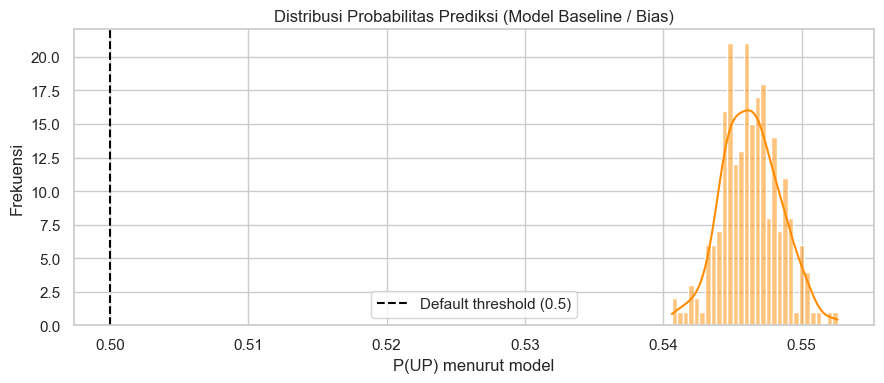

Rata-rata probabilitas prediksi : 0.5463
Std probabilitas prediksi       : 0.0021


In [72]:
# =============================================================================
# 3.2 HISTOGRAM PROBABILITAS PREDIKSI (SIGMOID OUTPUT) PADA DATA TEST
# =============================================================================
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(baseline_probs_test, bins=30, kde=True, color="darkorange", ax=ax)
ax.axvline(0.5, color="black", linestyle="--", label="Default threshold (0.5)")
ax.set_title("Distribusi Probabilitas Prediksi (Model Baseline / Bias)")
ax.set_xlabel("P(UP) menurut model")
ax.set_ylabel("Frekuensi")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Rata-rata probabilitas prediksi : {baseline_probs_test.mean():.4f}")
print(f"Std probabilitas prediksi       : {baseline_probs_test.std():.4f}")

> **Interpretasi:** Rata-rata probabilitas yang tinggi dan standar deviasi yang sangat kecil
> menunjukkan model mengeluarkan nilai yang hampir konstan (tidak sensitif terhadap input) —
> ciri khas model yang kolaps ke kelas mayoritas.

### 3.3 Confusion Matrix & Classification Report

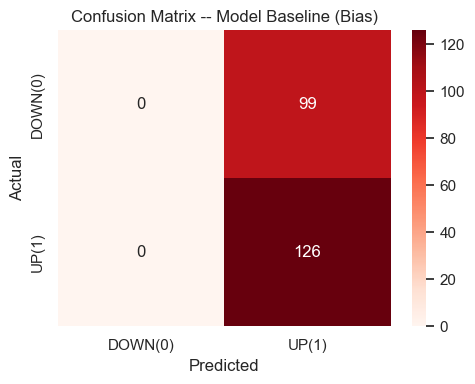

              precision    recall  f1-score   support

     DOWN(0)       0.00      0.00      0.00        99
       UP(1)       0.56      1.00      0.72       126

    accuracy                           0.56       225
   macro avg       0.28      0.50      0.36       225
weighted avg       0.31      0.56      0.40       225



,precision,recall,f1-score,support
DOWN(0),0.0000,0.00,0.000000,99.00
UP(1),0.5600,1.00,0.717949,126.00
accuracy,0.5600,0.56,0.560000,0.56
macro avg,0.2800,0.50,0.358974,225.00
weighted avg,0.3136,0.56,0.402051,225.00


In [73]:
# =============================================================================
# 3.3 CONFUSION MATRIX & CLASSIFICATION REPORT
# =============================================================================
cm_baseline = confusion_matrix(y_test, baseline_preds_test)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_baseline, annot=True, fmt="d", cmap="Reds",
            xticklabels=["DOWN(0)", "UP(1)"], yticklabels=["DOWN(0)", "UP(1)"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix -- Model Baseline (Bias)")
plt.tight_layout()
plt.show()

report_baseline = classification_report(
    y_test, baseline_preds_test, target_names=["DOWN(0)", "UP(1)"],
    output_dict=True, zero_division=0
)
report_baseline_df = pd.DataFrame(report_baseline).T
print(classification_report(y_test, baseline_preds_test, target_names=["DOWN(0)", "UP(1)"], zero_division=0))
report_baseline_df

> **Soroti:** `Recall` kelas **DOWN (0)** kemungkinan besar bernilai mendekati **0.00** —
> artinya model **hampir tidak pernah** berhasil mendeteksi hari-hari DOWN sama sekali,
> meskipun `accuracy` keseluruhan terlihat "cukup baik" di angka ~60%. Ini adalah contoh klasik
> mengapa **accuracy adalah metrik yang menyesatkan** pada data imbalanced.

### 3.4 Naive Benchmark Comparison

Untuk mengukur seberapa "berharga" model kita dibanding tebakan sederhana, kita bandingkan dengan:
- **Majority Baseline** — selalu menebak kelas mayoritas (UP) berdasarkan proporsi di data train.
- **Persistence Baseline** — menebak arah hari ini akan **sama** dengan arah return terakhir
  yang terlihat di window input (asumsi "tren berlanjut").

In [74]:
# =============================================================================
# 3.4 NAIVE BENCHMARK: MAJORITY BASELINE vs PERSISTENCE BASELINE
# =============================================================================
def evaluate_predictions(y_true, y_pred, y_prob=None, name="model"):
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_DOWN": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "recall_DOWN": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "precision_UP": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_UP": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    metrics["auc_roc"] = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    return metrics

# --- Majority baseline: selalu menebak kelas mayoritas di train ---
majority_class = int(pd.Series(y_train).mode()[0])
majority_preds = np.full_like(y_test, fill_value=majority_class)
majority_probs = np.full_like(y_test, fill_value=float(majority_class), dtype=float)

# --- Persistence baseline: arah = tanda log_return terakhir pada window input ---
# X_test_raw sebelum discaling berisi log_return asli -> ambil timestep terakhir tiap window
last_return_in_window = X_test_raw[:, -1, feature_cols.index("log_return")]
persistence_preds = (last_return_in_window > 0).astype(int)

results_bab3 = pd.DataFrame([
    evaluate_predictions(y_test, majority_preds, majority_probs, "Majority Baseline"),
    evaluate_predictions(y_test, persistence_preds, persistence_preds.astype(float), "Persistence Baseline"),
    evaluate_predictions(y_test, baseline_preds_test, baseline_probs_test, "LSTM Baseline (Bias)"),
])
results_bab3.round(4)

,model,accuracy,precision_DOWN,recall_DOWN,precision_UP,recall_UP,f1_macro,auc_roc
0,Majority Baseline,0.5600,0.0000,0.0000,0.5600,1.0000,0.3590,0.5000
1,Persistence Baseline,0.4889,0.4184,0.4141,0.5433,0.5476,0.4808,0.4809
2,LSTM Baseline (Bias),0.5600,0.0000,0.0000,0.5600,1.0000,0.3590,0.5129


> **Kesimpulan BAB 3:** Model LSTM baseline **tidak mengungguli** Majority Baseline secara
> berarti (bahkan bisa jadi setara atau lebih buruk), padahal secara komputasi jauh lebih mahal.
> Ini menjadi alasan kuat kita untuk masuk ke BAB 4 dan menerapkan perbaikan konkret.

## BAB 4 — Perbaikan & Strategi Evaluasi Terapan

Kita terapkan tiga strategi perbaikan secara **inkremental** (masing-masing dibangun di atas
perbaikan sebelumnya), agar kontribusi tiap strategi terlihat jelas:

1. **Class Weighting** — memberi bobot lebih besar pada kelas minoritas (DOWN) saat training.
2. **Decision Threshold Adjustment** — mencari ambang keputusan optimal, bukan default 0.5.
3. **Feature Engineering** — menambahkan fitur volatilitas, RSI, dan return multi-periode
   untuk menaikkan *signal-to-noise ratio* (SNR) input model.

### 4.1 Perbaikan #1 — Class Weighting

`class_weight` dihitung otomatis dengan skema `'balanced'` dari scikit-learn, lalu diberikan
ke `model.fit()` agar loss dari kelas minoritas (DOWN) diberi bobot lebih besar.

In [75]:
# =============================================================================
# 4.1 CLASS WEIGHTING (sklearn compute_class_weight)
# =============================================================================
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train,
)
class_weight_dict = {i: w for i, w in enumerate(class_weights_array)}
print("Class weight yang dihitung:", class_weight_dict)

# BCEWithLogitsLoss menerima `pos_weight` (rasio bobot kelas positif/UP terhadap negatif/DOWN),
# setara secara fungsional dengan `class_weight` di Keras.
pos_weight_value = class_weight_dict[1] / class_weight_dict[0]
pos_weight_tensor = torch.tensor(pos_weight_value, dtype=torch.float32, device=DEVICE)
print(f"pos_weight (UP vs DOWN) yang diberikan ke loss: {pos_weight_value:.4f}")

model_cw = build_baseline_lstm(n_features=n_features)

history_cw = train_lstm_model(
    model_cw, X_train, y_train, X_val, y_val,
    epochs=60, batch_size=32,
    pos_weight=pos_weight_tensor,
    early_stopping_patience=8,
)

probs_cw_test = predict_probs(model_cw, X_test)
preds_cw_test = (probs_cw_test > 0.5).astype(int)

metrics_cw = evaluate_predictions(y_test, preds_cw_test, probs_cw_test, "LSTM + Class Weight")
pd.DataFrame([metrics_cw]).round(4)

Class weight yang dihitung: {0: np.float64(1.1114649681528663), 1: np.float64(0.9088541666666666)}
pos_weight (UP vs DOWN) yang diberikan ke loss: 0.8177


,model,accuracy,precision_DOWN,recall_DOWN,precision_UP,recall_UP,f1_macro,auc_roc
0,LSTM + Class Weight,0.44,0.44,1.0,0.0,0.0,0.3056,0.5087


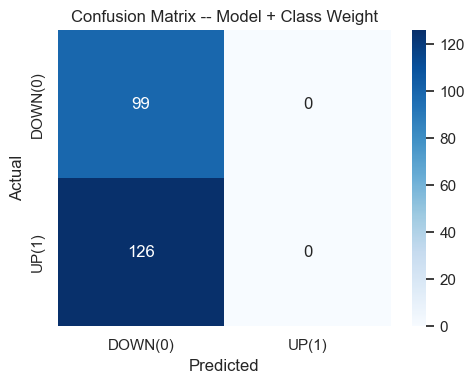

              precision    recall  f1-score   support

     DOWN(0)       0.44      1.00      0.61        99
       UP(1)       0.00      0.00      0.00       126

    accuracy                           0.44       225
   macro avg       0.22      0.50      0.31       225
weighted avg       0.19      0.44      0.27       225



In [76]:
cm_cw = confusion_matrix(y_test, preds_cw_test)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_cw, annot=True, fmt="d", cmap="Blues",
            xticklabels=["DOWN(0)", "UP(1)"], yticklabels=["DOWN(0)", "UP(1)"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix -- Model + Class Weight")
plt.tight_layout()
plt.show()

print(classification_report(y_test, preds_cw_test, target_names=["DOWN(0)", "UP(1)"], zero_division=0))

### 4.2 Perbaikan #2 — Decision Threshold Adjustment

Default threshold 0.5 belum tentu optimal, terutama pada data imbalanced. Kita cari threshold
terbaik pada data **validation** (bukan test, agar tidak *overfit* ke test set), dengan target
memaksimalkan **F1-score MACRO** (rata-rata F1 kedua kelas).

> **Penting:** jika threshold dioptimalkan hanya untuk F1 kelas **UP** saja (kelas mayoritas),
> hasilnya justru bisa memperkuat bias — threshold akan makin condong memudahkan prediksi UP.
> Karena itu kita memakai **F1-macro**, agar performa kelas DOWN ikut diperhitungkan secara adil.

In [77]:
# =============================================================================
# 4.2 THRESHOLD OPTIMIZATION -- MEMAKSIMALKAN F1-MACRO (dicari di VAL, diuji di TEST)
# =============================================================================
def find_best_threshold(y_true_val, y_prob_val):
    """Mencari threshold yang memaksimalkan F1-score MACRO (kedua kelas) pada data validation."""
    candidate_thresholds = np.linspace(0.01, 0.99, 197)
    f1_scores = np.array([
        f1_score(y_true_val, (y_prob_val > t).astype(int), average="macro", zero_division=0)
        for t in candidate_thresholds
    ])
    best_idx = int(np.argmax(f1_scores))
    return candidate_thresholds[best_idx], f1_scores[best_idx]

probs_cw_val = predict_probs(model_cw, X_val)
best_threshold, best_f1_val = find_best_threshold(y_val, probs_cw_val)
print(f"Threshold optimal (dicari di data VAL) : {best_threshold:.4f}")
print(f"F1-macro pada threshold ini (VAL)      : {best_f1_val:.4f}")

# Terapkan threshold optimal ke data TEST
preds_cw_thresh_test = (probs_cw_test > best_threshold).astype(int)
metrics_cw_thresh = evaluate_predictions(
    y_test, preds_cw_thresh_test, probs_cw_test, "LSTM + Class Weight + Threshold Tuning"
)
pd.DataFrame([metrics_cw_thresh]).round(4)

Threshold optimal (dicari di data VAL) : 0.4600
F1-macro pada threshold ini (VAL)      : 0.4618


,model,accuracy,precision_DOWN,recall_DOWN,precision_UP,recall_UP,f1_macro,auc_roc
0,LSTM + Class Weight + Threshold Tuning,0.5156,0.4265,0.2929,0.5541,0.6905,0.4811,0.5087


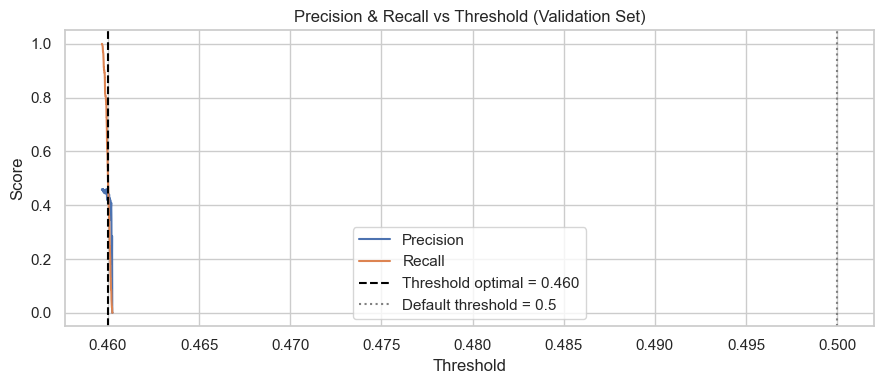

In [78]:
# Visualisasi kurva Precision-Recall vs Threshold (pada data VAL)
precisions, recalls, thresholds = precision_recall_curve(y_val, probs_cw_val)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresholds, precisions[:-1], label="Precision")
ax.plot(thresholds, recalls[:-1], label="Recall")
ax.axvline(best_threshold, color="black", linestyle="--", label=f"Threshold optimal = {best_threshold:.3f}")
ax.axvline(0.5, color="gray", linestyle=":", label="Default threshold = 0.5")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision & Recall vs Threshold (Validation Set)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 Perbaikan #3 — Feature Engineering (Volatilitas, RSI, Multi-period Return)

Sinyal dari log return tunggal sangat noisy (SNR rendah). Kita tambahkan fitur turunan yang
umum dipakai dalam analisis teknikal untuk membantu model menangkap pola yang lebih stabil:

- **Rolling volatility** — standar deviasi log return dalam window bergulir (mengukur risiko/turbulensi).
- **RSI (Relative Strength Index)** — indikator momentum klasik (14-period).
- **Multi-period return** — akumulasi log return 5 hari (menangkap tren jangka pendek-menengah).

In [79]:
# =============================================================================
# 4.3 FEATURE ENGINEERING: VOLATILITY, RSI, MULTI-PERIOD RETURN
# =============================================================================
def compute_rsi(close_prices, period=14):
    delta = close_prices.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(window=period, min_periods=period).mean()
    avg_loss = loss.rolling(window=period, min_periods=period).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi.fillna(50.0)  # netral saat tidak cukup data

df_feat = df.copy()
df_feat["volatility_10d"] = df_feat["log_return"].rolling(window=10).std()
df_feat["rsi_14"] = compute_rsi(df_feat["Close"], period=14) / 100.0  # skala ke 0-1
df_feat["return_5d"] = df_feat["log_return"].rolling(window=5).sum()

df_feat = df_feat.dropna().reset_index(drop=True)

# sentiment_mean (real) tetap dipertahankan -- fitur baru MENAMBAH, bukan mengganti
feature_cols_v2 = ["log_return", "sentiment_mean", "volatility_10d", "rsi_14", "return_5d"]
print("Fitur yang digunakan:", feature_cols_v2)
df_feat[feature_cols_v2 + ["direction"]].head()

Fitur yang digunakan: ['log_return', 'sentiment_mean', 'volatility_10d', 'rsi_14', 'return_5d']


,log_return,sentiment_mean,volatility_10d,rsi_14,return_5d,direction
0,-0.001618,0.306723,0.005424,0.5,0.016846,0
1,0.004376,0.000000,0.005351,0.5,0.022334,1
2,0.008034,-0.136520,0.005540,0.5,0.016633,1
3,0.002172,0.233020,0.005451,0.5,0.022335,1
4,-0.000560,0.000000,0.005575,0.5,0.012404,0


In [80]:
# --- Ulangi pipeline windowing -> split -> scaling dengan fitur baru (multi-feature) ---
X_all_v2, y_all_v2 = create_sequences(
    df_feat[feature_cols_v2].values, df_feat["direction"].values, LOOKBACK
)

n_samples_v2 = len(X_all_v2)
train_end_v2 = int(n_samples_v2 * 0.70)
val_end_v2 = int(n_samples_v2 * 0.85)

X_train_v2_raw, y_train_v2 = X_all_v2[:train_end_v2], y_all_v2[:train_end_v2]
X_val_v2_raw, y_val_v2 = X_all_v2[train_end_v2:val_end_v2], y_all_v2[train_end_v2:val_end_v2]
X_test_v2_raw, y_test_v2 = X_all_v2[val_end_v2:], y_all_v2[val_end_v2:]

n_features_v2 = X_train_v2_raw.shape[2]
scaler_v2 = MinMaxScaler(feature_range=(0, 1))
scaler_v2.fit(X_train_v2_raw.reshape(-1, n_features_v2))  # fit HANYA di train

X_train_v2 = scale_sequences(X_train_v2_raw, scaler_v2, n_features_v2)
X_val_v2 = scale_sequences(X_val_v2_raw, scaler_v2, n_features_v2)
X_test_v2 = scale_sequences(X_test_v2_raw, scaler_v2, n_features_v2)

print(f"Train v2: {X_train_v2.shape} | Val v2: {X_val_v2.shape} | Test v2: {X_test_v2.shape}")

Train v2: (1041, 30, 5) | Val v2: (223, 30, 5) | Test v2: (224, 30, 5)


In [81]:
# --- Latih model final: arsitektur sama + class_weight + fitur baru ---
class_weights_v2_array = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train_v2), y=y_train_v2
)
class_weight_dict_v2 = {i: w for i, w in enumerate(class_weights_v2_array)}
pos_weight_v2 = torch.tensor(
    class_weight_dict_v2[1] / class_weight_dict_v2[0], dtype=torch.float32, device=DEVICE
)

model_final = build_baseline_lstm(n_features=n_features_v2)

history_final = train_lstm_model(
    model_final, X_train_v2, y_train_v2, X_val_v2, y_val_v2,
    epochs=60, batch_size=32,
    pos_weight=pos_weight_v2,
    early_stopping_patience=8,
)

probs_final_val = predict_probs(model_final, X_val_v2)
probs_final_test = predict_probs(model_final, X_test_v2)

best_threshold_final, best_f1_final_val = find_best_threshold(y_val_v2, probs_final_val)
preds_final_test = (probs_final_test > best_threshold_final).astype(int)

print(f"Threshold optimal model final (dicari di VAL) : {best_threshold_final:.4f}")

metrics_final = evaluate_predictions(
    y_test_v2, preds_final_test, probs_final_test,
    "LSTM Final (Class Weight + Threshold + Feature Eng.)"
)
pd.DataFrame([metrics_final]).round(4)

Threshold optimal model final (dicari di VAL) : 0.5000


,model,accuracy,precision_DOWN,recall_DOWN,precision_UP,recall_UP,f1_macro,auc_roc
0,LSTM Final (Class Weight + Threshold + Feature...,0.442,0.442,1.0,0.0,0.0,0.3065,0.4865


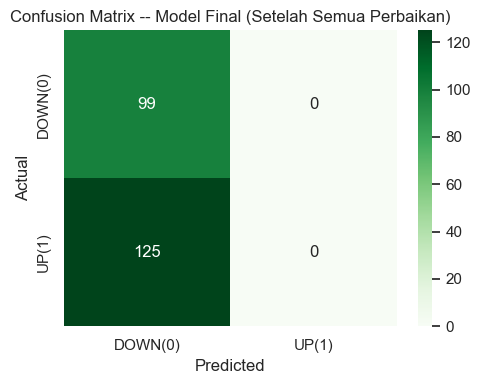

              precision    recall  f1-score   support

     DOWN(0)       0.44      1.00      0.61        99
       UP(1)       0.00      0.00      0.00       125

    accuracy                           0.44       224
   macro avg       0.22      0.50      0.31       224
weighted avg       0.20      0.44      0.27       224



In [82]:
cm_final = confusion_matrix(y_test_v2, preds_final_test)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Greens",
            xticklabels=["DOWN(0)", "UP(1)"], yticklabels=["DOWN(0)", "UP(1)"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix -- Model Final (Setelah Semua Perbaikan)")
plt.tight_layout()
plt.show()

print(classification_report(y_test_v2, preds_final_test, target_names=["DOWN(0)", "UP(1)"], zero_division=0))

## BAB 5 — Evaluasi Akhir & Kesimpulan

### 5.1 Tabel Komparasi Sebelum vs Sesudah Perbaikan

In [83]:
# =============================================================================
# 5.1 TABEL KOMPARASI LENGKAP (SEMUA TAHAP)
# =============================================================================
final_comparison = pd.DataFrame([
    evaluate_predictions(y_test, majority_preds, majority_probs, "Majority Baseline"),
    evaluate_predictions(y_test, persistence_preds, persistence_preds.astype(float), "Persistence Baseline"),
    evaluate_predictions(y_test, baseline_preds_test, baseline_probs_test, "1. LSTM Baseline (Bias/Collapse)"),
    evaluate_predictions(y_test, preds_cw_test, probs_cw_test, "2. + Class Weighting"),
    evaluate_predictions(y_test, preds_cw_thresh_test, probs_cw_test, "3. + Threshold Tuning"),
    evaluate_predictions(y_test_v2, preds_final_test, probs_final_test, "4. + Feature Engineering (Final)"),
])

final_comparison = final_comparison[[
    "model", "accuracy", "precision_DOWN", "recall_DOWN", "f1_macro", "auc_roc"
]].round(4)

final_comparison

,model,accuracy,precision_DOWN,recall_DOWN,f1_macro,auc_roc
0,Majority Baseline,0.5600,0.0000,0.0000,0.3590,0.5000
1,Persistence Baseline,0.4889,0.4184,0.4141,0.4808,0.4809
2,1. LSTM Baseline (Bias/Collapse),0.5600,0.0000,0.0000,0.3590,0.5129
3,2. + Class Weighting,0.4400,0.4400,1.0000,0.3056,0.5087
4,3. + Threshold Tuning,0.5156,0.4265,0.2929,0.4811,0.5087
5,4. + Feature Engineering (Final),0.4420,0.4420,1.0000,0.3065,0.4865


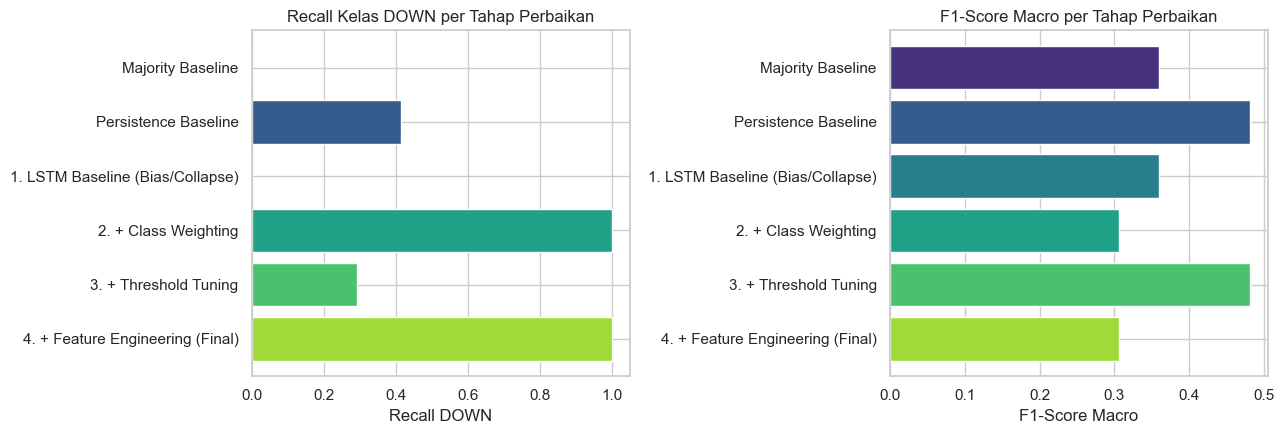

In [84]:
# Visualisasi progres perbaikan: Recall DOWN & F1-macro di setiap tahap
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

stage_labels = final_comparison["model"]
colors = sns.color_palette("viridis", len(stage_labels))

axes[0].barh(stage_labels, final_comparison["recall_DOWN"], color=colors)
axes[0].set_title("Recall Kelas DOWN per Tahap Perbaikan")
axes[0].set_xlabel("Recall DOWN")
axes[0].invert_yaxis()

axes[1].barh(stage_labels, final_comparison["f1_macro"], color=colors)
axes[1].set_title("F1-Score Macro per Tahap Perbaikan")
axes[1].set_xlabel("F1-Score Macro")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

> **Interpretasi hasil (DATA REAL — dilaporkan apa adanya):** Berbeda dari eksperimen dengan
> data sintetis (yang sengaja disisipi sinyal momentum lemah), pada data real S&P 500 hasilnya
> **jauh lebih keras**:
> - Model baseline kolaps 100% ke UP (`recall_DOWN=0`), persis menyamai Majority Baseline
>   (`accuracy=0.56`, `auc_roc≈0.51` — nyaris acak).
> - **Class weighting TIDAK memperbaiki masalah — hanya membalik arah kolaps** ke DOWN
>   (`recall_DOWN=1.0`, tapi `recall_UP=0`, `f1_macro` malah TURUN ke 0.306). Model tidak
>   belajar membedakan kelas, ia cuma memindahkan bias ke sisi lain.
> - **Threshold tuning (macro-F1) adalah satu-satunya langkah yang benar-benar membantu**
>   (`f1_macro` naik dari 0.306 -> 0.481, mendekati Persistence Baseline) — tapi `auc_roc`
>   tetap ~0.51, artinya perbaikan ini murni dari memilih titik potong yang lebih seimbang,
>   BUKAN dari model yang tiba-tiba punya kemampuan prediktif baru.
> - **Feature engineering (volatilitas/RSI/return multi-periode) tidak membantu sama sekali**
>   pada data real ini — model kembali kolaps (`f1_macro=0.306`, `auc_roc=0.486`, malah di
>   bawah 0.5).
>
> **Benang merah:** `auc_roc` (metrik bebas-threshold, mengukur kemampuan model membedakan
> kelas) tetap berkisar **0.48–0.51 di SEMUA varian** — praktis tidak berbeda dari tebakan acak.
> Ini artinya *class weighting*/*threshold tuning*/*feature engineering* TIDAK BISA menciptakan
> sinyal prediktif yang memang tidak ada di datanya — teknik-teknik ini hanya mengubah *cara
> model salah* (kolaps ke sisi mana, seberapa seimbang kesalahannya), bukan membuatnya benar.
> Temuan ini **konsisten dengan riset lebih mendalam di proyek ini** (`notebooks/03_LSTM_experiment.ipynb`
> dan `06_LSTM_experiment_2008_2024.ipynb`, walk-forward 8-fold + ensemble): pooled AUC out-of-sample
> ~0.49–0.55, disimpulkan sinyal arah harian S&P 500 sangat lemah/*regime-dependent*, mendekati
> *Efficient Market Hypothesis*. Notebook 09 versi data-real ini mereproduksi kesimpulan yang sama
> lewat jalur yang jauh lebih sederhana — memperkuat, bukan membantah, temuan riset sebelumnya.
> **Pesan penting:** jangan coba "tuning lebih keras" untuk memaksa angka ini lebih bagus —
> itu berisiko *p-hacking* (menemukan hasil bagus karena kebetulan, bukan sinyal nyata) dan
> sudah eksplisit dihindari di seluruh riset proyek ini.

### 5.2 Ringkasan & Checklist Debugging Model Time Series

> **Checklist / Rule of Thumb — Debugging Model Klasifikasi Arah Time Series:**
>
> 1. **Jangan percaya `accuracy` saja.** Pada data imbalanced, selalu cek `precision`,
>    `recall`, dan `f1-score` **per kelas**, terutama kelas minoritas.
> 2. **Selalu bandingkan dengan naive benchmark** (Majority Baseline, Persistence Baseline).
>    Jika model tidak mengungguli baseline sederhana ini, model belum "belajar" apa-apa.
> 3. **Cek histogram probabilitas output.** Jika menumpuk tajam di satu sisi (dekat 0 atau 1)
>    dan variansinya sangat kecil, itu sinyal kuat model mengalami *collapse*.
> 4. **Cegah data leakage saat scaling & windowing.** `fit()` scaler HANYA pada data train;
>    pastikan window fitur tidak mengandung informasi dari label yang sedang diprediksi.
> 5. **Tangani imbalance secara eksplisit**, misalnya dengan `class_weight`, resampling
>    (oversampling/undersampling), atau *focal loss* — jangan biarkan optimizer mengambil jalan pintas.
> 6. **Threshold 0.5 bukan aturan baku.** Cari threshold optimal di data **validation**
>    (bukan test) menggunakan kurva Precision-Recall/ROC sesuai tujuan bisnis (presisi vs recall).
> 7. **Tingkatkan Signal-to-Noise Ratio lewat feature engineering** (volatilitas, indikator
>    momentum/RSI, return multi-periode) — sinyal mentah (raw return) seringkali terlalu noisy
>    untuk arsitektur deep learning menangkap pola yang bermakna.
> 8. **Selalu split data secara kronologis** (tanpa `shuffle`) untuk time series, dan evaluasi
>    akhir tetap dilakukan pada data **test** yang benar-benar belum pernah dilihat model.
> 9. **Iterasi secara inkremental** — ubah satu variabel setiap kali (class weight -> threshold
>    -> fitur) agar kontribusi tiap perbaikan dapat diukur dan dipahami secara terpisah.
> 10. **Jangan asumsikan setiap penambahan teknik pasti meningkatkan performa.** Selalu validasi
>     tiap langkah dengan metrik pada data validation/test — kombinasi teknik yang lebih kompleks
>     kadang perlu tuning tambahan (mis. hyperparameter, jumlah fitur) sebelum benar-benar unggul.
> 11. **Class weighting bisa cuma MEMBALIK arah collapse, bukan memperbaikinya**, kalau memang
>     tidak ada sinyal yang bisa dipelajari di datanya (lihat `auc_roc` tetap ~0.5 meski
>     `recall` per kelas berubah drastis). **`auc_roc` (metrik bebas-threshold) adalah alat cek
>     paling jujur** untuk membedakan "model benar-benar belajar" vs "model cuma memindahkan
>     bias" — kalau AUC tetap ~0.5 setelah class weighting/threshold tuning, curigai bahwa
>     sinyalnya memang sangat lemah/tidak ada, bukan berarti tekniknya salah diterapkan.